# If you really feel lost without ROOT

<img src="root.png">

## Disclosure:

Andrea strongly disagree with the ROOT using under python (maybe the ROOT usage in general)

<img src="rootevil.png">

## You can import ROOT in python

If you setted correctly also the `PYTHONPATH` environment variable
(the `thisroot.sh` script should)

In [1]:
!echo $PYTHONPATH

/usr/local/lib/python:/usr/local/Cellar/root/6.18.00/lib/root


In [2]:
import sys
for s in sys.path:
    if "root" in s:
        print(s)

/usr/local/Cellar/root/6.18.00/lib/root


### And then you can use ROOT in python

In [3]:
import ROOT

Welcome to JupyROOT 6.18/00


Essentially in the same way as in C++

In [4]:
h = ROOT.TH1F("h2","h2",100,-20,20)

In [5]:
h.FillRandom('gaus',1000)

In [6]:
c = ROOT.TCanvas("c","c",800,600)

In [7]:
h.Draw()

You have to `Draw` the TCanvas to see something...

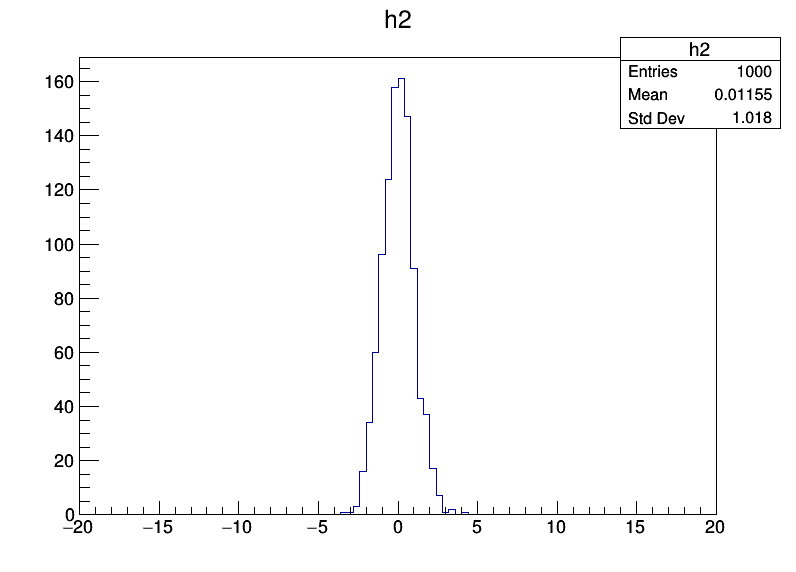

In [8]:
c.Draw()

You can also use an interactive viewer (which is not working in the slideshow mode)

In [9]:
ROOT.enableJSVis()

In [10]:
c.Draw()

In [11]:
ROOT.disableJSVis()

## Pay attention!!

ROOT is not throwing an exception if there is an error in reading the file

It just prints a message

In [12]:
file = ROOT.TFile('nonexisting.root','READ')

Error in <TFile::TFile>: file nonexisting.root does not exist


then if you read the file in a verbose script you may not see the error and it can keep running...

Let me suggest you to wrap the ROOT function to raise an exception in case the file reading has problems:

In [26]:
def my_read_rootfile(filename):
    inputfile = ROOT.TFile(filename,'READ')
    if not inputfile.IsOpen():
        raise FileNotFoundError("file",filename,"not found")
    if inputfile.IsZombie():
        raise OSError("error opening the file",filename)
        
my_read_rootfile('nonexisting.root')

FileNotFoundError: [Errno file] nonexisting.root: 'not found'

Error in <TFile::TFile>: file nonexisting.root does not exist


## `root_numpy`

`root_numpy` is a Python extension module that provides an efficient interface between ROOT and numpy. `root_numpy`’s internals are compiled C++ and can therefore handle large amounts of data much faster than equivalent pure Python implementations

You need ROOT installed anyway

In [14]:
from root_numpy import root2array, testdata

In [15]:
filepath = '/Users/carlo/repos/C12fragmentation-G4-new/build/CC62b0-85_dt05_XSfree7_500pt_0.root'

You can import into a numpy array deciding wich branches you want to import, define a selection on them and how many events

In [16]:
arr = root2array(filepath,'tree',
                branches=['EventNumber','nSec','Ek','A','Z','b','ExcitationE','theta','phi','cos(theta)'],
                selection='b>1',
                start=0, stop=20, step=2)

`root_numpy` correctly throws exception in case of problems:

In [17]:
arr2 = root2array('nonexisting.root','tree',
                branches=['EventNumber','nSec','Ek','A','Z','b','ExcitationE','theta','phi','cos(theta)'],
                selection='b>1',
                start=0, stop=20, step=2)

OSError: unable to access tree 'tree' in nonexisting.root

Error in <TFile::TFile>: file nonexisting.root does not exist


## Let's have a look of the output

In [18]:
arr

array([(1, 14,   1.69690495, 1, 1, 4.011, -1.,  45.6612309 ,   74.24988029, -0.1079268 ),
       (1, 14,   6.29808691, 4, 2, 4.011,  0.,  67.76151353,  -18.17192348,  0.21556606),
       (1, 14, 186.03385006, 4, 2, 4.011,  0.,  10.88564924,  -14.08491321, -0.1097038 ),
       (1, 14,  41.83970772, 1, 0, 4.011, -1.,  22.09368475,  129.10815968, -0.99474777),
       (1, 14, 110.71854027, 1, 0, 4.011, -1.,  21.83089652,  -77.98799257, -0.98718709),
       (1, 14,  46.92782496, 1, 1, 4.011, -1.,  39.16901489, -176.97694698,  0.10072219),
       (1, 14,   5.30059794, 1, 1, 4.011, -1., 122.48945396,  150.33044389, -0.99946672),
       (2, 20,  12.78839706, 2, 1, 1.55 ,  0.,  48.29599304,   85.98112386, -0.38821427),
       (2, 20,  35.69547059, 1, 0, 1.55 , -1.,   8.07353228,  -56.63549748, -0.21779108)],
      dtype=[('EventNumber', '<i4'), ('nSec', '<i4'), ('Ek', '<f8'), ('A', '<i4'), ('Z', '<i4'), ('b', '<f8'), ('ExcitationE', '<f8'), ('theta', '<f8'), ('phi', '<f8'), ('cos(theta)', '<f8'

## A closer look

In [19]:
arr.shape

(9,)

In [20]:
type(arr)

numpy.ndarray

You can access the first entry:

In [21]:
arr[0]

(1, 14, 1.69690495, 1, 1, 4.011, -1., 45.6612309, 74.24988029, -0.1079268)

And one of its variables:

In [22]:
arr[0]['Ek']

1.6969049537191268

but also all the entries in a branch:

In [23]:
arr['Ek']

array([  1.69690495,   6.29808691, 186.03385006,  41.83970772,
       110.71854027,  46.92782496,   5.30059794,  12.78839706,
        35.69547059])

# `root_pandas`

In [3]:
from root_pandas import read_root

In [5]:
filepath = '/Users/carlo/repos/C12fragmentation-G4-new/build/CC62b0-85_dt05_XSfree7_500pt_0.root'
df = read_root(filepath, columns=['EventNumber','nSec','Ek','A','Z','b','ExcitationE','theta','phi'])

In [6]:
df.head()

,EventNumber,nSec,Ek,A,Z,b,ExcitationE,theta,phi
0,0,1,6.080882e-09,12,6,-1.000,0.0,89.999833,-61.642126
1,1,14,3.781918e+00,2,1,4.011,0.0,56.031974,-171.235878
2,1,14,1.696905e+00,1,1,4.011,-1.0,45.661231,74.249880
3,1,14,3.754434e-01,1,0,4.011,-1.0,113.413500,-4.587722
4,1,14,6.298087e+00,4,2,4.011,0.0,67.761514,-18.171923


Also `root_pandas` has problems with `TString`

In [7]:
df2 = read_root(filepath)

TypeError: cannot convert leaf 'G4version' of branch 'G4version' with type 'TString'